# 5. Units and measurement uncertainty

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/05_units_and_uncertainty.ipynb)

Two jobs every lab report needs, and both are mechanical enough to hand to SymPy:

- converting units and checking that a formula is dimensionally consistent
- propagating measurement uncertainty through a formula

**Worked example:** the uncertainty of a viscosity measured with a capillary viscometer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sympy.physics import units as u

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (6.4, 4),
})

## 5.1 Unit conversion

A unit is a symbol that multiplies a number. `convert_to` rewrites a quantity in the units you ask for.

In [2]:
speed = 60 * u.mile / u.hour
u.convert_to(speed, u.meter / u.second).n(5)

26.822⋅meter
────────────
   second   

In [3]:
u.convert_to(100 * u.psi, u.bar).n(5), u.convert_to(u.atmosphere * u.liter, u.joule).n(6)

(6.8948⋅bar, 101.325⋅joule)

Physical constants are built in, with units attached. The gas constant in three unit systems:

In [4]:
R_gas = u.molar_gas_constant
[u.convert_to(R_gas, target).n(6) for target in (
    [u.joule, u.mol, u.kelvin],
    [u.liter, u.bar, u.mol, u.kelvin],
    [u.liter, u.atmosphere, u.mol, u.kelvin],
)]

⎡8.31446⋅joule  0.0831446⋅bar⋅liter  0.0820574⋅atmosphere⋅liter⎤
⎢─────────────, ───────────────────, ──────────────────────────⎥
⎣ kelvin⋅mole       kelvin⋅mole             kelvin⋅mole        ⎦

## 5.2 Checking that a group is dimensionless

Attach units to every quantity and convert to base units. If only a number is left, the group
is dimensionless, and the mixed units have been handled for you.

Water flowing at 1.2 m/s in a 2-inch pipe:

In [5]:
SI_base = [u.kilogram, u.meter, u.second]

density = 998 * u.kilogram / u.meter**3
velocity = 1.2 * u.meter / u.second
diameter = 2 * u.inch
viscosity = 1.0e-3 * u.pascal * u.second

reynolds = u.convert_to(density * velocity * diameter / viscosity, SI_base)
assert reynolds.is_number          # no units left
reynolds

60838.0800000000

A wrong formula leaves units behind. Suppose the diameter was forgotten:

In [6]:
u.convert_to(density * velocity / viscosity, SI_base)       # 1/meter: not dimensionless

1197600.0
─────────
  meter  

`check_dimensions` catches the other classic error, adding quantities of different kinds.

In [7]:
from sympy.physics.units.util import check_dimensions

try:
    check_dimensions(3 * u.meter + 2 * u.second)
except ValueError as err:
    print("ValueError:", str(err)[:45], "...")

ValueError: addends have incompatible dimensions: {((Dime ...


**Limits of `sympy.physics.units`.** It is convenient for conversions and consistency checks, but
it has rough edges. Use the named units (`u.mm`, `u.kPa`, `u.cm`, …) and avoid the generic
prefixes (`u.milli * u.meter`) and user-defined units, which do not always convert correctly.
For heavy numerical work with units, the [`pint`](https://pint.readthedocs.io) package is the
usual choice. A good habit either way: convert everything to SI at the start, compute, and
convert the answer at the end.

In [8]:
assert u.convert_to(250 * u.kPa, u.pascal) == 250000 * u.pascal
u.convert_to(250 * u.kPa, u.bar), u.convert_to(2 * u.inch, u.mm).n(4)

⎛5⋅bar                 ⎞
⎜─────, 50.8⋅millimeter⎟
⎝  2                   ⎠

## 5.3 Propagation of uncertainty

If $f$ depends on measured quantities $x_i$ with independent standard uncertainties $\sigma_i$,
then to first order

$$\sigma_f^2 = \sum_i \left(\frac{\partial f}{\partial x_i}\right)^2 \sigma_i^2 .$$

The partial derivatives are the tedious part. SymPy takes them all at once:

In [9]:
def propagate(f, uncertainties):
    """Standard uncertainty of f, given {symbol: its uncertainty symbol or value}."""
    return sp.sqrt(sum((sp.diff(f, x) * s) ** 2 for x, s in uncertainties.items()))

## 5.4 Worked example: a capillary viscometer

**Problem.** A liquid is pushed through a capillary of radius $R$ and length $L$ by a pressure
drop $\Delta P$, and the flow rate $Q$ is measured. The Hagen–Poiseuille law gives the viscosity:

$$\mu = \frac{\pi\,\Delta P\,R^4}{8\,Q\,L}$$

Which measurement limits the accuracy of $\mu$?

In [10]:
dP, R, Q, L = sp.symbols("Delta_P R Q L", positive=True)
s_dP, s_R, s_Q, s_L = sp.symbols("sigma_Delta_P sigma_R sigma_Q sigma_L", positive=True)

mu = sp.pi * dP * R**4 / (8 * Q * L)
sigmas = {dP: s_dP, R: s_R, Q: s_Q, L: s_L}

sigma_mu = propagate(mu, sigmas)
relative = sp.simplify(sigma_mu / mu)
relative

   ______________________________________________________________________
  ╱    2  2  2    2      2  2  2    2    2  2 ⎛      2    2    2      2⎞ 
╲╱  Δ_P ⋅L ⋅R ⋅σ_Q  + Δ_P ⋅Q ⋅R ⋅σ_L  + L ⋅Q ⋅⎝16⋅Δ_P ⋅σ_R  + R ⋅σ_Δ_P ⎠ 
─────────────────────────────────────────────────────────────────────────
                                Δ_P⋅L⋅Q⋅R                                

**By hand** you would expect, for a product of powers,

$$\left(\frac{\sigma_\mu}{\mu}\right)^2 = \left(\frac{\sigma_{\Delta P}}{\Delta P}\right)^2
+ 16\left(\frac{\sigma_R}{R}\right)^2 + \left(\frac{\sigma_Q}{Q}\right)^2 + \left(\frac{\sigma_L}{L}\right)^2 ,$$

and the SymPy result agrees:

In [11]:
expected = (s_dP / dP) ** 2 + 16 * (s_R / R) ** 2 + (s_Q / Q) ** 2 + (s_L / L) ** 2
assert sp.simplify(relative**2 - expected) == 0

The factor 16 comes from $R^4$: a 1 % error in the radius becomes a 4 % error in the viscosity.

**Numbers.** Measured values and their standard uncertainties, in SI units:

In [12]:
measured = {dP: 5000.0, R: 0.50e-3, Q: 1.2e-6, L: 0.100}          # Pa, m, m^3/s, m
uncert = {s_dP: 50.0, s_R: 0.005e-3, s_Q: 0.018e-6, s_L: 0.5e-3}  # 1 %, 1 %, 1.5 %, 0.5 %

mu_val = float(mu.subs(measured))
sigma_val = float(sigma_mu.subs({**measured, **uncert}))
print(f"mu = ({mu_val * 1e3:.3f} ± {sigma_val * 1e3:.3f}) mPa·s   ({sigma_val / mu_val:.1%})")

mu = (1.023 ± 0.045) mPa·s   (4.4%)


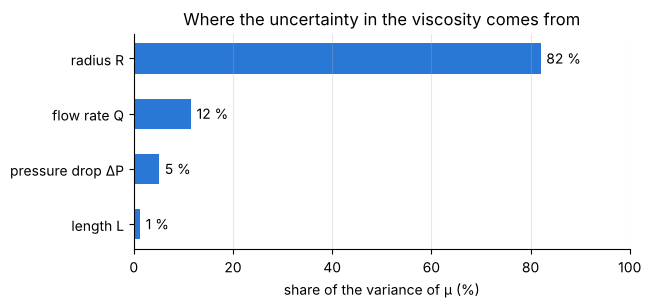

In [13]:
# share of each measurement in the variance of mu
names = {dP: "pressure drop ΔP", R: "radius R", Q: "flow rate Q", L: "length L"}
shares = {
    names[x]: float(((sp.diff(mu, x) * s) ** 2 / sigma_mu**2).subs({**measured, **uncert}))
    for x, s in sigmas.items()
}
assert abs(sum(shares.values()) - 1) < 1e-12

order = sorted(shares, key=shares.get)
fig, ax = plt.subplots(figsize=(6.4, 2.8))
bars = ax.barh(order, [100 * shares[n] for n in order], color="#2a78d6", height=0.55)
ax.bar_label(bars, fmt="%.0f %%", padding=4)
ax.set(xlabel="share of the variance of μ (%)", xlim=(0, 100),
       title="Where the uncertainty in the viscosity comes from")
ax.grid(axis="y", visible=False)

The radius, although measured as precisely as the pressure, is responsible for about four fifths
of the uncertainty. Money spent on a better flow meter would be wasted; calibrating the capillary
radius is what improves the result.

**Verify with a Monte Carlo simulation.** Draw many random "experiments" from the measurement
distributions and look at the spread of the computed viscosity. No derivatives are involved, so
this is an independent check.

In [14]:
rng = np.random.default_rng(seed=1)
N = 200_000
samples = [rng.normal(measured[x], uncert[s], N) for x, s in sigmas.items()]

mu_fun = sp.lambdify(list(sigmas), mu, "numpy")     # fast numerical version of the formula
mu_samples = mu_fun(*samples)

print(f"propagation formula: {sigma_val / mu_val:.2%}")
print(f"Monte Carlo:         {mu_samples.std() / mu_samples.mean():.2%}")
assert abs(mu_samples.std() / sigma_val - 1) < 0.03

propagation formula: 4.42%
Monte Carlo:         4.40%


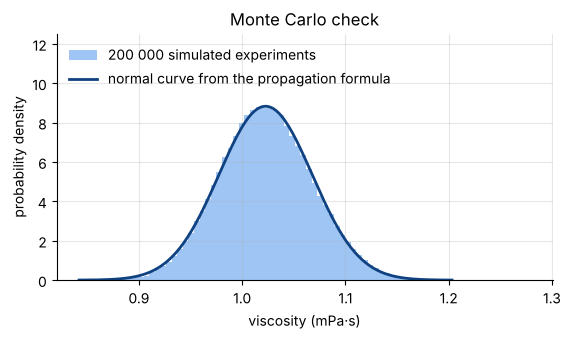

In [15]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.hist(mu_samples * 1e3, bins=80, density=True, color="#9ec5f4", label="200 000 simulated experiments")
grid = np.linspace(mu_val - 4 * sigma_val, mu_val + 4 * sigma_val, 200)
ax.plot(grid * 1e3, np.exp(-0.5 * ((grid - mu_val) / sigma_val) ** 2) / (sigma_val * 1e3 * np.sqrt(2 * np.pi)),
        color="#104281", lw=2, label="normal curve from the propagation formula")
ax.set(xlabel="viscosity (mPa·s)", ylabel="probability density", title="Monte Carlo check")
ax.set_ylim(top=1.35 * ax.get_ylim()[1])
ax.legend(frameon=False, loc="upper left");

The two agree. The propagation formula is a first-order approximation, so it becomes less
accurate when uncertainties are large (above roughly 10 %) or the formula is strongly nonlinear.
In those cases trust the Monte Carlo result.

## Exercises

1. Convert a heat-transfer coefficient of 25 W/(m²·K) to SI base units, and a density of
   62.4 lb/ft³ to kg/m³.
2. Attach units to the Stokes settling velocity of notebook 1 and confirm it comes out in m/s.
3. A pendulum of length $L = 1.000 \pm 0.002$ m has a period $T = 2.007 \pm 0.005$ s. Find
   $g = 4\pi^2 L / T^2$ and its uncertainty. Which measurement should be improved?
4. The density of a cylinder is $\rho = 4m/(\pi d^2 h)$. Derive the relative uncertainty with
   `propagate` and compare it with the product-of-powers rule.
5. Repeat the Monte Carlo check with the radius uncertainty raised to 10 %. Compare the
   standard deviation and the mean of the simulated viscosities with the propagation result.
   Is the distribution still symmetric?